# import lib

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms
from PIL import Image, ImageFile
from tqdm import tqdm  # comman library use to tracking loop
from torchvision.utils import save_image
from pathlib import Path

import os

ImageFile.LOAD_TRUNCATED_IMAGES = True

# Utilis

In [2]:
class ImageFolderDataset(Dataset):
    def __init__(self, root, transform=None):
        super(ImageFolderDataset, self).__init__()
        self.root = Path(root)
        self.transform = transform

        self.files = []

        for path  in self.root.rglob('*'):

            # skip dir
            if not path.is_file():
                continue

            # check image extension
            if path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
                continue

            # check whether image can actually be loaded
            try:
                with Image.open(path) as img:
                    img.load()
                    
                self.files.append(path)
                
            except Exception as e:
                print(f"Skipping corrupted image: {path}")
                print(f"Reason: {e}")

        print(f"Found {len(self.files)} vaild images in {self.root}")

    def __len__(self):
        return len(self.files)
    
    def __getitem__(self, index):
        image_path = self.files[index]
        image = Image.open(image_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        return image

In [3]:
""" Extract the statistical signature mean & std of an image layer """
def calc_mean_std(feat, eps=1e-5):
    
    # gets structural dim of the incoming feature map tensor
    size = feat.size() # [batch_size, channels, h, w]

    assert (len(size) == 4) # safty check, ensures the tensor is exactly 4-dim

    batch_size, channels = size[:2]

    feat_mean = feat.view(batch_size, channels, -1).mean(dim=2).view(batch_size, channels, 1, 1)
    feat_var = feat.view(batch_size, channels, -1).var(dim=2, unbiased=False) + eps
    feat_std = feat_var.sqrt().view(batch_size,channels, 1, 1)
    
    # feat_mean => calculate average color position
    # feat_std => calc texture strength
    return feat_mean, feat_std

In [4]:

""" takes content layout and paints the style statistics right over it"""
def adaptive_instance_normalization(content_feat, style_feat):
    # [batch_size, channels, h, w]
    size = content_feat.size()

    style_mean, style_std = calc_mean_std(style_feat) # extract artistic style signature
    content_mean, content_std = calc_mean_std(content_feat) # extract original lighting and texture signature
    
    """ Wiping the Slate clean - Normalization"""
    # .expand(size): stretches and duplicate, [1, 512, 1, 1] => [1, 512, 28, 28]
    # subtraction : subtracts the average brightness from every pixel. this erase the original color casting and lighting.
    # Divides every pixel by the origin std, this flattens out the original image's texture and native contrast.
    # normalized_content_feat is now a blank structural blueprint centered at a mean of 0 and variance of 1.
    normalized_content_feat = (content_feat - content_mean.expand(size)) / content_std.expand(size)

    """ Painting the new style """
    # style_std.expand(size): Stretches the artwork's contrast/texture value to match the image dimensions.
    # normalized_content_feat * style_std...: Multiplies the blank blueprint by the artwork's standard deviation. This injects the brushstroke crispness and texture intensity of the style.
    # style_mean.expand(size): Stretches the artwork's color palette value to match the image dimensions.
    # + style_mean...: Shifts the values up or down by adding the style's mean. This injects the global color scheme and lighting palette of the artwork.
    return normalized_content_feat * style_std.expand(size) + style_mean.expand(size)

# VGG-19 Encoder architecture

In [5]:
# define the standard VGG-19 Encoder architecture (Convolutional backbone of VGG-19)
class VGGEncoder(nn.Module):
    def __init__(self, vgg_path):
        super(VGGEncoder, self).__init__()

        # Define the complete VGG-19 structure so the weights file fits perfectly
            # all Relu are the checkpoints inside the brain of the VGG network. Each checkpoint sees our image at a different level of details.
            # VGG devide into 5 major blocks and each block have multiple convolutional layers.
            # as we go from Block 1 to 5: the network zoom out, shrinking the image size but looking at bigger patterns. 
        self.vgg = nn.Sequential(
            nn.Conv2d(3, 3, (1, 1)), # 1x1 convolution acts as a learnable color space or normalization transformation, before feature extraction starts.
            nn.ReflectionPad2d((1, 1, 1, 1)), #  Reflection padding mirrors the pixel values at the borders, instead of black border
            nn.Conv2d(3, 64, (3, 3)),
            nn.ReLU(), # relu1-1 (index: 3)

            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(64, 64, (3, 3)),
            nn.ReLU(), # relu1-2


            nn.MaxPool2d((2, 2),  (2, 2), (0, 0), ceil_mode=True), # ceil_mode -> handles odd-dimension spatial feature, ensure feature edge details are not cut off. 
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(64, 128, (3, 3)),
            nn.ReLU(), # relu2-1 (index: 10)
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(128, 128, (3, 3)),
            nn.ReLU(), # relu2-2

            # relu1 & relue2 => capture the fine texture of style painting | they see the tiny details.

            nn.MaxPool2d((2, 2), (2, 2), (0, 0), ceil_mode=True),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(128, 256, (3, 3)),
            nn.ReLU(), # relu3-1 (index: 17)
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(256, 256, (3, 3)),
            nn.ReLU(), # relu3-2
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(256, 256, (3, 3)),
            nn.ReLU(), # relu3-3
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(256, 256, (3, 3)),
            nn.ReLU(), # relu3-4
            
            # relu3 => it sees complex textures and geometric arrangments. and start recognizing wave patterns, repetitive tile shapes, and shading. 

            nn.MaxPool2d((2, 2), (2, 2), (0, 0), ceil_mode=True),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(256, 512, (3, 3)),
            nn.ReLU(), # relu4-1 (index: 30), this is the last layer used - Content layer

            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(512, 512, (3, 3)),
            nn.ReLU(), # relu4-2
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(512, 512, (3, 3)),
            nn.ReLU(), # relu4-3
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(512, 512, (3, 3)),
            nn.ReLU(), # relu4-4

            nn.MaxPool2d((2, 2), (2, 2), (0, 0), ceil_mode=True),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(512, 512, (3, 3)),
            nn.ReLU(), # relu5-1
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(512, 512, (3, 3)),
            nn.ReLU(), # relu5-2
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(512, 512, (3, 3)),
            nn.ReLU(), # relu5-3
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(512, 512, (3, 3)),
            nn.ReLU(), # relu5-4
        )
        
        # load the pre-trained weights
        self.vgg.load_state_dict(torch.load(vgg_path))
        self.vgg = nn.Sequential(*list(self.vgg.children())[:31]) # take only first 31 layers (index 0 -> 30 relu4-1)
        
        # splitting VGG into 4 seprate Mini-networks 
        enc_layers = list(self.vgg.children())
        self.enc_1 = nn.Sequential(*enc_layers[:4]) # ends at relu1-1
        self.enc_2 = nn.Sequential(*enc_layers[4:11]) # ends at relu2-1
        self.enc_3 = nn.Sequential(*enc_layers[11:18]) # ends at relu3-1
        self.enc_4 = nn.Sequential(*enc_layers[18:31]) # ends at relu4-1

        # freeze all parameters :- because VGG is not train
        for name in ['enc_1', 'enc_2', 'enc_3', 'enc_4']:
            for param in getattr(self, name).parameters():
                param.requires_grad = False
        
    def forward(self, input, test=False):
        h1 = self.enc_1(input)
        h2 = self.enc_2(h1)
        h3 = self.enc_3(h2)
        h4 = self.enc_4(h3)

        # h1,h2,h3 => only used to loss compute
        if test:
            return h4
        return h1, h2, h3, h4

## Pretraind VGG-19 download

In [6]:
!wget -O /kaggle/working/vgg_normalised.pth \
https://github.com/naoto0804/pytorch-AdaIN/releases/download/v0.0.0/vgg_normalised.pth

--2026-09-25 18:28:05--  https://github.com/naoto0804/pytorch-AdaIN/releases/download/v0.0.0/vgg_normalised.pth
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/112338125/d6ae2603-8f3e-4c58-98af-1a248448781e?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-09-25T19%3A08%3A50Z&rscd=attachment%3B+filename%3Dvgg_normalised.pth&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-09-25T18%3A08%3A04Z&ske=2026-09-25T19%3A08%3A50Z&sks=b&skv=2018-11-09&sig=l1bmuUDin3FAEvjqNphoSrZtrW3EbicYKhBUd3Y%2FCYY%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MDM2MjY4NSwibmJmIjoxNzkwMzYwODg1LCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZH

# Decoder

In [7]:
class Decoder(nn.Module):
    def __init__(self):
        super(Decoder, self).__init__()
        self.decoder = nn.Sequential(
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(512, 256, (3, 3)),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(256, 256, (3, 3)),
            nn.ReLU(),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(256, 256, (3, 3)),
            nn.ReLU(),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(256, 256, (3, 3)),
            nn.ReLU(),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(256, 128, (3, 3)),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(128, 128, (3, 3)),
            nn.ReLU(),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(128, 64, (3, 3)),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(64, 64, (3, 3)),
            nn.ReLU(),
            nn.ReflectionPad2d((1, 1, 1, 1)),
            nn.Conv2d(64, 3, (3, 3)),
        )

    def forward(self, input):
        return self.decoder(input) 

In [8]:
# content data set download
!wget -c http://images.cocodataset.org/zips/test2017.zip

--2026-09-25 18:28:06--  http://images.cocodataset.org/zips/test2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 16.15.183.116, 52.217.126.26, 52.217.207.122, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|16.15.183.116|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6646970404 (6.2G) [application/zip]
Saving to: ‘test2017.zip’

test2017.zip        100%[===================>]   6.19G  54.3MB/s    in 2m 3s   

2026-09-25 18:30:09 (51.4 MB/s) - ‘test2017.zip’ saved [6646970404/6646970404]



# device setup

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [10]:
# load dataset on working dir
import zipfile

content_zip_path = "/kaggle/working/test2017.zip"
style_zip_path = "/kaggle/input/competitions/painter-by-numbers/train_1.zip"

content_dir = Path("/kaggle/working/content")
style_dir = Path("/kaggle/working/style")

content_dir.mkdir(parents=True, exist_ok=True)
style_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(content_zip_path, 'r') as z:
    z.extractall(content_dir)

with zipfile.ZipFile(style_zip_path, 'r') as z:
    z.extractall(style_dir)

print("Done")

Done


In [11]:

batch_size = 4 # 16

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.ToTensor()
])

content_dataset = ImageFolderDataset(content_dir, transform=transform)
style_dataset = ImageFolderDataset(style_dir, transform=transform)

print("Content: ", len(content_dataset))
print("Style: ", len(style_dataset))

content_dataloader = DataLoader(
    content_dataset, batch_size=batch_size, shuffle=True, drop_last=True
)

style_dataloader = DataLoader(
    style_dataset, batch_size=batch_size, shuffle=False, drop_last=True
)

Found 40670 vaild images in /kaggle/working/content


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (107327830 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Found 11025 vaild images in /kaggle/working/style
Content:  40670
Style:  11025


# Training
## Training Setup

In [12]:
lr= 0.0001
lr_decay= 5e-05
epochs= 2 # 30
style_weight= 10
content_weight= 1.0
log_interval= 1
save_interval= 2

In [13]:
vgg_path = "/kaggle/working/vgg_normalised.pth"

encoder = VGGEncoder(vgg_path).to(device)
decoder = Decoder().to(device)

optimizer = optim.Adam(decoder.parameters(), lr=lr)

scheduler = optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda epoch: 1.0 / (1.0 + (lr_decay * epoch))
)

mse_loss = torch.nn.MSELoss()

## Training start

In [14]:
save_dir = Path('/kaggle/working/experiment/01')
save_dir.mkdir(parents=True, exist_ok=True)

In [15]:
encoder.eval()

running_loss = None
running_closs = None
running_sloss = None

for epoch in range(epochs):
    progress_bar = tqdm(zip(content_dataloader, style_dataloader),
                       total=min(len(content_dataloader), len(style_dataloader)))

    running_loss=0
    running_closs=0
    running_sloss=0

    for content_batch, style_batch in progress_bar:
        
        content_batch = content_batch.to(device)
        style_batch = style_batch.to(device)

        # every image go through encoder 
        c_features = encoder(content_batch)
        s_features = encoder(style_batch)

        # AdaIn layer
        t = adaptive_instance_normalization(c_features[-1], s_features[-1])

        # decoder
        g = decoder(t)

        g_features = encoder(g)
        
        loss_c = mse_loss(g_features[-1], t) * content_weight

        loss_s = 0
        for g_f, s_f in zip(g_features, s_features):
            g_mean, g_std = calc_mean_std(g_f)
            s_mean, s_std = calc_mean_std(s_f)
            loss_s += mse_loss(g_mean, s_mean) + mse_loss(g_std, s_std)

        loss_s = loss_s * style_weight

        loss = loss_c + loss_s        

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        progress_bar.set_description(f'Iter {epoch+1}: Loss: {running_loss:4f}, Content Loss: {running_closs:4f}, Style loss: {running_sloss:4f}')

        running_loss += loss.item()
        running_closs += loss_c.item()
        running_sloss += loss_s.item()

    scheduler.step() # change the lr

    running_loss /= len(content_dataloader)
    running_closs /= len(content_dataloader)
    running_sloss /= len(content_dataloader)

    if (epoch+1) % log_interval == 0:
        tqdm.write(f'Iter {epoch+1}: Loss: {running_loss:4f}, Content Loss: {running_closs:4f}, Style loss: {running_sloss:4f}')

    if (epoch+1) % save_interval == 0:
        torch.save(decoder.state_dict(), save_dir / f'decoder_{epoch+1}.pth')
        
        with torch.no_grad():
            output = torch.cat([content_batch, style_batch, g], dim=0)
            save_image(output, save_dir / f'output_{epoch+1}.png', nrow=batch_size)

Iter 1: Loss: 72197.233334, Content Loss: 7159.557865, Style loss: 65037.675424: 100%|██████████| 2756/2756 [13:33<00:00,  3.39it/s]


Iter 1: Loss: 7.102406, Content Loss: 0.704383, Style loss: 6.398023


Iter 2: Loss: 41700.332399, Content Loss: 6171.157689, Style loss: 35529.174705: 100%|██████████| 2756/2756 [13:36<00:00,  3.37it/s]


Iter 2: Loss: 4.102677, Content Loss: 0.607152, Style loss: 3.495526


Displaying: /kaggle/working/experiment/01/output_2.png


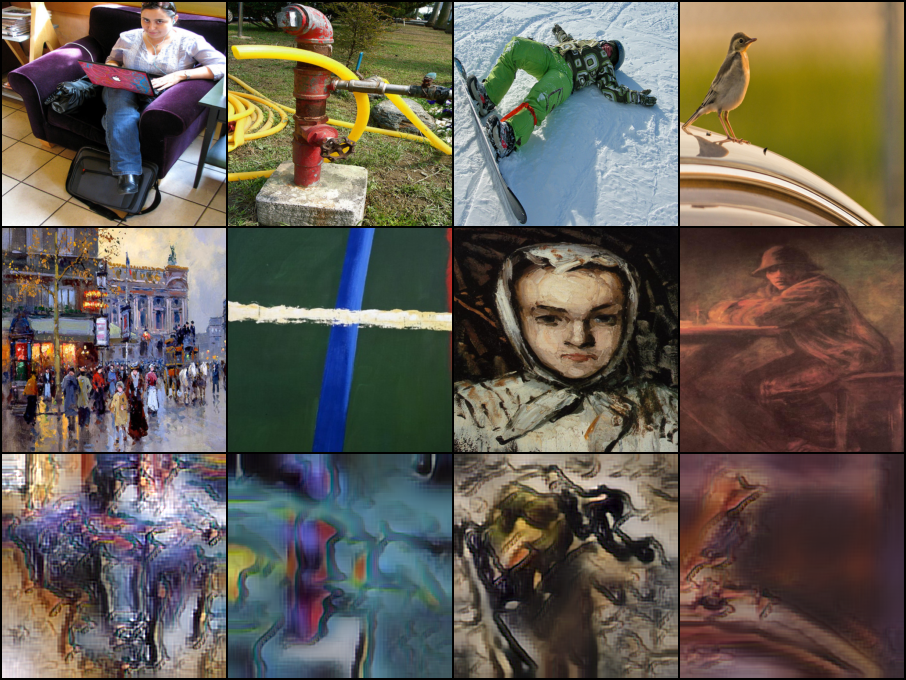

In [16]:
from IPython import display

images = list(save_dir.glob('output_*.png'))

if images:
    latest_img = max(images, key=lambda x: int(x.stem.split('_')[1] ))
    print(f"Displaying: {latest_img}")
    display.display(
        display.Image(filename=str(latest_img))
    )
else:
    print("No output image found")